# Multimarginal Quantum Optimal Transport by Regularized Semidefinite Programming
___

## Problem

Let $\mathcal{H}$ be a $d$-dimensional Hilbert space and $N \ge 2$, and write the joint space as
$\mathcal{H}_1 \otimes \cdots \otimes \mathcal{H}_N$, where every $\mathcal{H}_j$ is a copy of $\mathcal{H}$ and the label only records the slot.
For $\Gamma \in \mathbb{H}(\mathcal{H}_1 \otimes \cdots \otimes \mathcal{H}_N)$ the $i$-th marginal $\operatorname{Tr}^{i}[\Gamma] \in \mathbb{H}(\mathcal{H}_i)$ is the partial trace over every factor but $\mathcal{H}_i$, the upper index naming the factor that is kept; it is defined by
$$
\operatorname{Tr}\bigl[\Gamma\,(\mathrm{I}_{\mathcal{H}_1} \otimes \cdots \otimes U \otimes \cdots \otimes \mathrm{I}_{\mathcal{H}_N})\bigr] \ = \ \operatorname{Tr}\bigl[U\, \operatorname{Tr}^{i}[\Gamma]\bigr]
\qquad \text{for every } U \in \mathbb{H}(\mathcal{H}_i),
$$
with $U$ in the $i$-th slot and $\mathrm{I}_{\mathcal{H}}$ denotes identity matrix on $\mathcal{H}$. For $N = 2$ these are the two marginals of [1, (2.1)]. Given density
matrices $\rho_1, \dots, \rho_N$ on $\mathcal{H}$ (i.e. positive matrices with unit trace), we write $\Gamma \mapsto (\rho_1, \dots, \rho_N)$ if $\Gamma \in \mathbb{H}_{\ge}(\mathcal{H}_1 \otimes \cdots \otimes \mathcal{H}_N)$
and $\operatorname{Tr}^{i}[\Gamma] = \rho_i$ for every $i$; such $\Gamma$ are called couplings, and $\rho_1 \otimes \cdots \otimes \rho_N$ is a particular choice.

Quantum optimal transport is the problem of finding the coupling of least cost for a cost $C \in \mathbb{H}(\mathcal{H}_1 \otimes \cdots \otimes \mathcal{H}_N)$,
$$
\mathrm{QOT}(\rho_1, \dots, \rho_N) \ := \ \min\bigl\{ \operatorname{Tr}[C\Gamma] \ : \ \Gamma \mapsto (\rho_1, \dots, \rho_N) \bigr\}.
$$
It is a instance of semidefinite programming, since objective and constraints are linear and we have PSD constraint on $\Gamma$.

## Regularization

In the following, we will solve this problem numerically by adding regularization term.

Fix $\varepsilon > 0$ and a convex, superlinear, bounded-below $\varphi : [0, +\infty) \to \mathbb{R}$ [1, (2.6)], acting on
operators through their eigenvalues, and add a spectral penalty to the objective [1, (2.7), (2.10)]:
$$
\mathrm{F}^\varepsilon(\Gamma) \ = \ \operatorname{Tr}[C\Gamma] \ + \ \varepsilon \operatorname{Tr}[\varphi(\Gamma)].
$$
Then, we solve convex-regularized QOT problem

$$
\mathrm{QOT}^{\varepsilon}(\rho_1, \dots, \rho_N) \ := \ \min\bigl\{ \mathrm{F}^\varepsilon(\Gamma) \ : \ \Gamma \mapsto (\rho_1, \dots, \rho_N) \bigr\}.
$$


## Dual problem

The dual variables are potentials $U = (U_1, \dots, U_N)$, $U_i \in \mathbb{H}(\mathcal{H}_i)$, one per marginal. Define their Kronecker sum
$$
U_1 \oplus \cdots \oplus U_N \ = \ \sum_{i=1}^{N} \mathrm{I}_{\mathcal{H}_1} \otimes \cdots \otimes U_i \otimes \cdots \otimes \mathrm{I}_{\mathcal{H}_N}
$$
which is the adjoint operator of taking partial traces $\Gamma \mapsto (\operatorname{Tr}^{1}[\Gamma], \dots, \operatorname{Tr}^{N}[\Gamma])$.

The dual problem objective is given by
$$
\mathrm{D}^\varepsilon(U_1, \dots, U_N) \ = \ \sum_{i=1}^{N} \operatorname{Tr}[U_i \rho_i] \ - \ \varepsilon \operatorname{Tr}\left[ \psi\left( \frac{U_1 \oplus \cdots \oplus U_N - C}{\varepsilon} \right) \right],
$$
and the dual problem of $\mathrm{QOT}^{\varepsilon}(\rho_1, \dots, \rho_N)$ is
$$
    \sup_{U_i \in \mathbb{H}(\mathcal{H}_i)} \mathrm{D}^\varepsilon(U_1, \dots, U_N)
$$

If every $\rho_i$ is positive definite, the maximum of $\mathrm{D}^\varepsilon$ equals the minimum of $\mathrm{F}^\varepsilon$, a
maximizer $U^*$ exists, and the optimal coupling is unique and given by [1, Theorem 2.3, (2.17)]
$$
\Gamma^* \ = \ \psi'\left( \frac{U_1^* \oplus \cdots \oplus U_N^* - C}{\varepsilon} \right).
$$

Differentiating $\mathrm{D}^\varepsilon(U_1, \dots, U_N)$ w.r.t. $U_i$ gives
$$
\nabla_{U_i} \mathrm{D}^\varepsilon(U_1, \dots, U_N) \ = \ \rho_i \ - \ \operatorname{Tr}^{i}\left[ \psi'\left( \frac{U_1 \oplus \cdots \oplus U_N - C}{\varepsilon} \right) \right],
$$
so the norm of the gradient measures violation of marginal constraint.

The maximizer is unique only up the gauge, i.e. $U_i \mapsto U_i + c_i\mathrm{I}_{\mathcal{H}_i}$ with $\sum_i c_i = 0$, gives another optimal point.

## Role of $\varepsilon$

As $\varepsilon \to 0$ the transport cost $\operatorname{Tr}[C\Gamma^*_\varepsilon]$ of the
regularized coupling approaches $\mathrm{QOT}(\rho_1, \dots, \rho_N)$ [1, Section 5].

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import optax
import jax
jax.config.update("jax_enable_x64", True)  # we need float64/complex128

from spacecore import Context
from sdplab import SDPProblem
from sdplab.special.qot import QOTConstraintOp
from sdplab.solvers import run_cvxpy_solver, run_regularized_solver
from sdplab import RegularizedSDPDualFunctional as RegFunc, EntropyReg, QuadraticReg
from sdplab.special.pauli import PauliSum, generate_single_pauli_string as pauli

## 1. Problem instance

We take $N = 4$ qubits, so $d = 2$ and a coupling is a $16 \times 16$ matrix. The cost is given by
$$
C \ = \ \sum_{i=1}^{N-1} \bigl( J_X\, X_i X_{i+1} \ + \ J_Z\, Z_i Z_{i+1} \bigr), \qquad J_X = 1, \ J_Z = 0.5,
$$
where $X_i$, $Z_i$ are Pauli matrices on site $i$.

In [4]:
ctx = Context('jax', dtype='complex128')

N, d = 4, 2
J_X, J_Z = 1.0, 0.5

# pauli("XXII", ctx) is the dense matrix of X (x) X (x) I (x) I
C = ctx.asarray(J_X * (pauli("XXII", ctx) + pauli("IXXI", ctx) + pauli("IIXX", ctx))
                + J_Z * (pauli("ZZII", ctx) + pauli("IZZI", ctx) + pauli("IIZZ", ctx)))

P = QOTConstraintOp(d=d, N=N, ctx=ctx)    # P(Gamma) = the N marginals of Gamma

print("C shape: ", C.shape)

C shape:  (16, 16)


### Data

The marginals are qubit states with Bloch vectors $r_i \in \mathbb{R}^3$,
$$
\rho_i \ = \ \tfrac12 \bigl( \mathrm{I}_{\mathcal{H}} + r_i^x X + r_i^y Y + r_i^z Z \bigr),
$$
To ensure that states are strictly positive, we require $\|r_i\| < 1$, since eigenvalues of $\rho_i$ are given by
$$
    \lambda_i = \frac{1 \pm \|r_i\|}{2}.
$$

In [5]:
bloch = [[0.20,  0.00,  0.00],
         [0.00,  0.15,  0.10],
         [0.00,  0.00, -0.25],
         [0.10, -0.10,  0.10]]

rho = ctx.asarray(np.stack([PauliSum(["I", "X", "Y", "Z"], [1.0, *r], ctx=ctx).materialize() / 2
                            for r in bloch]))

problem = SDPProblem(C, P, rho)

for i, r in enumerate(bloch):
    print(f"  rho_{i + 1}: Bloch vector {r}, eigenvalues {np.linalg.eigvalsh(np.asarray(rho[i])).round(3)}")

  rho_1: Bloch vector [0.2, 0.0, 0.0], eigenvalues [0.4 0.6]
  rho_2: Bloch vector [0.0, 0.15, 0.1], eigenvalues [0.41 0.59]
  rho_3: Bloch vector [0.0, 0.0, -0.25], eigenvalues [0.375 0.625]
  rho_4: Bloch vector [0.1, -0.1, 0.1], eigenvalues [0.413 0.587]


### Reference solution: SCS

CVXPY passes the unregularized program to SCS, an operator-splitting solver. Its value is
$\mathrm{QOT}(\rho_1, \dots, \rho_N)$, i.e. value of the unregularized problem.

In [6]:
Gamma_scs, U_scs = run_cvxpy_solver(problem, solver="SCS", eps=1e-10, max_iters=200_000)

QOT = float(np.trace(np.asarray(C) @ np.asarray(Gamma_scs)).real)
print("QOT = Tr[C Gamma_scs]       =", QOT)
print("max |P Gamma_scs - rho|    =", float(np.abs(np.asarray(P.apply(ctx.asarray(Gamma_scs))) - np.asarray(rho)).max()))
print("min eigenvalue             =", float(np.linalg.eigvalsh(np.asarray(Gamma_scs)).min()))

QOT = Tr[C Gamma_scs]       = -3.1205066781955013
max |P Gamma_scs - rho|    = 4.3298697960381105e-15
min eigenvalue             = -1.9456265466357108e-13


SCS returns a coupling whose marginals are exact to $4 \cdot 10^{-15}$. Its smallest eigenvalue, $-2 \cdot 10^{-13}$,
is at the solver's accuracy.

## 2. Entropy regularization

For $\varphi(t) = t(\log t - 1)$ we have $\psi(s) = \psi'(s) = e^{s}$, so the optimal coupling is the Gibbs state
$$
\Gamma^*_{\mathrm{vN}} \ = \ \frac{1}{Z(U^*)}\exp\left( \frac{U_1^* \oplus \cdots \oplus U_N^* - C}{\varepsilon} \right), \qquad
Z(U) = \operatorname{Tr}\exp\left( \frac{U_1 \oplus \cdots \oplus U_N - C}{\varepsilon} \right).
$$

In particular case of entropy, we can optimize much robust version of dual function which is given by
$$
\mathrm{D}^\varepsilon_{\log}(U) \ = \ \sum_{i=1}^{N} \operatorname{Tr}[U_i \rho_i] \ - \ \varepsilon \log Z(U) \ - \ \varepsilon .
$$
The gradient w.r.t. $U_i$ of the dual above is given by
$$
\nabla_{U_i} \mathrm{D}^\varepsilon_{\log}(U) \ = \ \rho_i \ - \ \frac{1}{Z(U)} \operatorname{Tr}^{i}\left[ \exp\left( \frac{U_1 \oplus \cdots \oplus U_N - C}{\varepsilon} \right) \right].
$$

In [33]:
EPS = 1.
reg_vn = EntropyReg(P.dom)

# bind() freezes eps and the normalization onto the functional, so that the value, the gradient
# and the recovered coupling can never be evaluated at different settings by accident.
#
# Normalization
D_vn = RegFunc(problem, reg_vn).bind(eps_val=EPS, normalized=True)

info_vn = run_regularized_solver(
    D_vn,
    method="optax",        # the compiled spacecore/optax loop
    opt=optax.lbfgs(),
    verbose=0,
    max_iter=10_000,
    tol=1e-10,             # tolerance on ||grad D_eps||, which is the marginal residual
)

Gamma_vn = D_vn.primal_from_dual(info_vn.dual)   # Gamma = psi'(slack / eps), normalized to unit trace

print("iterations              =", info_vn.num_iters)
print("Tr[Gamma_vn]            =", np.trace(np.asarray(Gamma_vn)).real)
print("max |P Gamma_vn - rho|  =", float(np.abs(np.asarray(P.apply(Gamma_vn) - rho)).max()))
print("min eigenvalue          =", float(np.linalg.eigvalsh(np.asarray(Gamma_vn)).min()))
print("eigenvalues below 1e-16:", int((np.linalg.eigvalsh(np.asarray(Gamma_vn)) < 1e-16).sum()))

iterations              = 21
Tr[Gamma_vn]            = 1.0000000000000013
max |P Gamma_vn - rho|  = 1.1314354168010823e-11
min eigenvalue          = 0.0001307405930609471
eigenvalues below 1e-16: 0


The coupling has unit trace and reproduces the four marginals to $1 \cdot 10^{-11}$ in 21 iterations. An exponential
has no zero eigenvalues, and at $\varepsilon = 1$ none comes near double precision: the smallest is $1.3 \cdot 10^{-4}$.

## 3. Quadratic regularization

For $\varphi(t) = t^2/2$ on $t \ge 0$ we have $\psi(s) = \max\{s,0\}^2/2$ and $\psi'(s) = \max\{s,0\}$, so
$$
\Gamma^*_{Q} \ = \ \left( \frac{U_1^* \oplus \cdots \oplus U_N^* - C}{\varepsilon} - \theta \right)_{+}
$$
is the positive part of an operator, where $\theta \in \mathbb{R}$ is the multiplier enforcing $\operatorname{Tr}\Gamma = 1$.

**`normalized=True` here.** Unlike the entropy case, $\theta$ cannot be factored out of a clip: the normalization is
carried out by optimizing over $\theta$ at every function evaluation.

In [34]:
reg_q = QuadraticReg(P.dom)
D_q = RegFunc(problem, reg_q).bind(eps_val=EPS, normalized=True)

info_q = run_regularized_solver(
    D_q, method="optax", opt=optax.lbfgs(), verbose=0, max_iter=10_000, tol=1e-10,
)

Gamma_q = D_q.primal_from_dual(info_q.dual)

print("iterations             =", info_q.num_iters)
print("Tr[Gamma_q]            =", np.trace(np.asarray(Gamma_q)).real)
print("max |P Gamma_q - rho|  =", float(np.abs(np.asarray(P.apply(Gamma_q) - rho)).max()))
print("min eigenvalue         =", float(np.linalg.eigvalsh(np.asarray(Gamma_q)).min()))
print("eigenvalues below 1e-16:", int((np.linalg.eigvalsh(np.asarray(Gamma_q)) < 1e-16).sum()))

iterations             = 41
Tr[Gamma_q]            = 0.9999999999999993
max |P Gamma_q - rho|  = 1.961342199763294e-11
min eigenvalue         = -3.114514723923991e-17
eigenvalues below 1e-16: 12


Twelve eigenvalues of the quadratic coupling lie below $10^{-16}$, compared to none of the entropy coupling.

## 4. Comparison

Three couplings of the same marginals are now available. We report in the table the transport cost $\operatorname{Tr}[C\Gamma]$, its
excess over $\mathrm{QOT}$, the von Neumann entropy $S(\Gamma) = -\operatorname{Tr}[\Gamma\log\Gamma]$, the Frobenius norm, and the numerical rank.

In [38]:
def von_neumann_entropy(Gamma):
    ev = np.clip(np.linalg.eigvalsh(np.asarray(Gamma)), 1e-300, None)
    return float(-np.sum(ev * np.log(ev)))


def frobenius(Gamma):
    return float(np.linalg.norm(np.asarray(Gamma)))


def numerical_rank(Gamma, tol=1e-16):
    return int((np.linalg.eigvalsh(np.asarray(Gamma)) > tol).sum())


def cost(Gamma):
    return problem.primal_objective(Gamma)


solutions = [
    ("SCS (no regularization)", Gamma_scs),
    ("L2 regularization", Gamma_q),
    ("Entropy regularization", Gamma_vn),
]

print(f"{'Solution type':<24s} | {'Tr[C Gamma]':>12s} | {'- QOT':>9s} | {'Entropy(Gamma)':>12s} | {'L2 norm':>8s} | {'rank':>4s}")
print(f"{'-'*24}-|-{'-'*12}-|-{'-'*9}-|-{'-'*14}-|-{'-'*8}-|-{'-'*4}")
for name, Gamma in solutions:
    print(f"{name:<24s} | {cost(Gamma):12.8f} | {cost(Gamma) - QOT:9.2e} | {von_neumann_entropy(Gamma):14.5f} | "
          f"{frobenius(Gamma):8.5f} | {numerical_rank(Gamma):4d}")

Solution type            |  Tr[C Gamma] |     - QOT | Entropy(Gamma) |  L2 norm | rank
-------------------------|--------------|-----------|----------------|----------|-----
SCS (no regularization)  |  -3.12050668 |  0.00e+00 |        0.39460 |  0.87600 |   12
L2 regularization        |  -3.03597059 |  8.45e-02 |        0.90849 |  0.68215 |    4
Entropy regularization   |  -2.51951760 |  6.01e-01 |        1.67553 |  0.51143 |   16


All three are couplings of the same marginals, so their costs are comparable. The quadratic coupling lies
$8 \cdot 10^{-2}$ above $\mathrm{QOT}$ and has rank three, lowest compared to SCS coupling and to entropy one. The entropic coupling pays $0.6$ and
has full rank with the largest entropy.

### Spectra

The two regularizers recover $\Gamma^*$ through different $\psi'$, so we plot the eigenvalues of the three couplings.

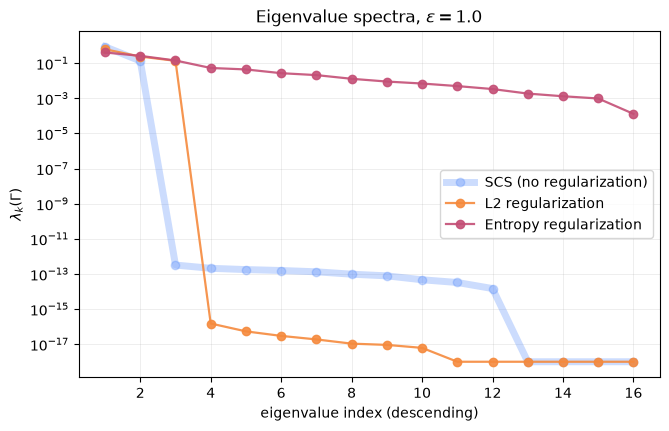

In [40]:
def plot_spectra(panels, suptitle, floor=1e-18):
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    for k, (name, Gamma) in enumerate(panels):
        ev = np.sort(np.linalg.eigvalsh(np.asarray(Gamma)))[::-1]
        # the reference is drawn thick and translucent, so a solution lying on top of it stays visible
        style = dict(lw=5, alpha=0.3) if k == 0 else dict(lw=1.6, alpha=0.9)
        ax.semilogy(np.arange(1, len(ev) + 1), np.clip(ev, floor, None), "o-", label=name, **style)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("eigenvalue index (descending)")
    ax.set_ylabel(r"$\lambda_k(\Gamma)$")
    ax.set_title(suptitle)
    ax.grid(alpha=0.3)
    ax.legend()
    return fig


plot_spectra(solutions, rf"Eigenvalue spectra, $\varepsilon = {EPS}$")
plt.show()

## 5. Convergence in $\varepsilon$

We now demonstrate how excess cost of the regularized coupling goes down as $\varepsilon \to 0$.

In [9]:
EPS_GRID = [1.0, 1e-1, 1e-2, 1e-3]


def solve(reg, eps):
    D_eps = RegFunc(problem, reg).bind(eps_val=eps, normalized=True)
    info = run_regularized_solver(
        D_eps, method="optax", opt=optax.lbfgs(), verbose=0, max_iter=10_000, tol=1e-10,
    )
    return D_eps.primal_from_dual(info.dual), info


excess = {name: [cost(solve(reg, eps)[0]) - QOT for eps in EPS_GRID]
          for name, reg in (("L2 regularization", reg_q), ("Entropy regularization", reg_vn))}

print(f"{'eps':<24s} | " + " | ".join(f"{e:>8g}" for e in EPS_GRID))
print(f"{'-'*24}-|-" + "-|-".join("-" * 8 for _ in EPS_GRID))
for name, values in excess.items():
    print(f"{name:<24s} | " + " | ".join(f"{v:8.2e}" for v in values))

eps                      |        1 |      0.1 |     0.01 |    0.001
-------------------------|----------|----------|----------|---------
L2 regularization        | 8.45e-02 | 8.17e-05 | 8.29e-07 | 8.24e-09
Entropy regularization   | 6.01e-01 | 1.02e-02 | 5.35e-06 | 5.39e-08


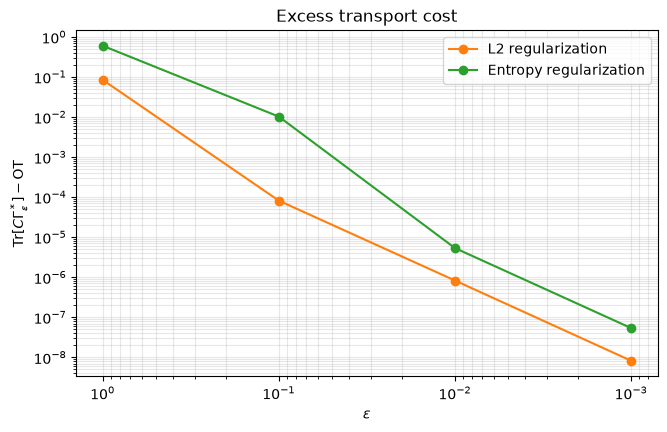

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for name, values in excess.items():
    color = "C1" if name.startswith("L2") else "C2"     # same colours as the spectra plot
    ax.loglog(EPS_GRID, values, "o-", color=color, label=name)
ax.invert_xaxis()                     # epsilon decreases to the right
ax.set_xlabel(r"$\varepsilon$")
ax.set_ylabel(r"$\mathrm{Tr}[C\Gamma^*_\varepsilon] - \mathrm{QOT}$")
ax.set_title("Excess transport cost")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

Both excesses are positive and decrease as $\varepsilon$ shrinks, to $8 \cdot 10^{-9}$ for quadratic regularization and $5 \cdot 10^{-8}$ for the
entropy at $\varepsilon = 10^{-3}$.

## References

[1] E. Caputo, A. Gerolin, N. Monina, L. Portinale, *Quantum optimal transport with convex regularization*,
J. Funct. Anal. 290(4), 111262 (2026), [arXiv:2409.03698](https://arxiv.org/abs/2409.03698). Notation, equation and
theorem numbers refer to this paper: the partial traces (2.1), the assumptions on $\varphi$ (2.6), the regularized
primal (2.7), (2.10), the Legendre transform (2.12), the dual (2.13), (2.15), duality and the optimal coupling
**Theorem 2.3** and (2.17), the derivative of $\operatorname{Tr}[\psi(\cdot)]$ (3.23), the quadratic regularizer **Example 3.1**.

[2] E. Caputo, A. Gerolin, N. Monina, P. Pelikh, L. Portinale, *Quantum thermodynamics and semidefinite
programming: regularization and algorithms*, [arXiv:2602.23144](https://arxiv.org/abs/2602.23144). **Theorem 2.5**
covers general linear constraints and $C^1$ $\psi$, hence $N$ marginals and the quadratic regularizer.

## IMPORTANT

`spacecore` and `sdplab` are recently new libraries and are in alpha stage.
If you spotted a bug, please report an issue or send an email to pavlopelikh@gmail.com